# Hwang et al. 2022 — PDAC
## Step 04 — EMT-TF expression (unconditional final step)

The EMT-TF readout is **unconditional** and always the last notebook (here 04, since Gate 3 = NA ended
the gate chain after 03). Score a wide mesenchymal-TF panel (Snail/Zeb/Twist **plus** FOXC/PRRX —
03_eval fork 5), gate on detectable expression, and overlay the root-end and terminus-end factors as
thresholded expressers on a grey manifold (categorical overlay, not a continuous colormap — 04_test
Sun2021).

In [1]:
import os, sys, warnings
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, scanpy as sc
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
sc.settings.verbosity = 1; SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4)); pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars'); pth_feat = os.path.join(pth_data, 'features', 'biomart')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

In [3]:
# read processed.h5ad (raw manifold) but reuse the linear layout + pseudotime from signatures
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime', round(t.min(),2), '->', round(t.max(),2))

cells: 64401 | pseudotime 0.0 -> 10.38


### Derive the EMT-TF pair — detection-gated, arm-specific

In [4]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn,1/3); late = tn >= np.quantile(tn,2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows=[]
for j,g in enumerate(present):
    x=X[:,j]; rho,p=spearmanr(tn,x)
    rows.append((g,round((x>0).mean(),3),round(x[early].mean(),3),round(x[late].mean(),3),round(rho,3)))
df=pd.DataFrame(rows,columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end']=np.where(df.mean_early>df.mean_late,'EARLY(root)','LATE(terminus)'); df=df.sort_values('rho_vs_t')
print(df.to_string(index=False))
ok=df[df.frac_expr>0.03]
early_tf=ok.sort_values('rho_vs_t').iloc[0]['TF']; late_tf=ok.sort_values('rho_vs_t').iloc[-1]['TF']
print(f'\nderived pair: {early_tf} (early/root) <-> {late_tf} (late/terminus); most-expressed = {df.sort_values("frac_expr").iloc[-1].TF}')

    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
 PRRX1      0.021       0.028      0.022    -0.039    EARLY(root)
 PRRX2      0.042       0.052      0.041    -0.038    EARLY(root)
  ZEB1      0.157       0.189      0.209    -0.012 LATE(terminus)
 FOXC2      0.004       0.003      0.004    -0.007 LATE(terminus)
 FOXC1      0.036       0.039      0.046    -0.005 LATE(terminus)
 SNAI1      0.001       0.000      0.001     0.004 LATE(terminus)
TWIST2      0.001       0.001      0.002     0.005 LATE(terminus)
TWIST1      0.001       0.001      0.003     0.015 LATE(terminus)
  ZEB2      0.020       0.015      0.032     0.026 LATE(terminus)
 SNAI2      0.021       0.012      0.039     0.066 LATE(terminus)

derived pair: PRRX2 (early/root) <-> FOXC1 (late/terminus); most-expressed = ZEB1


**Read:** modulation is weak in this PDAC manifold (small |rho| across the panel), consistent with
the low global module amplitude. Among detectably-expressed factors the extremes are **PRRX2** at the
Gast/pSom root end and **FOXC1** toward the terminus; **ZEB1** is the most broadly expressed EMT-TF
(~16% of cells).

### Deliverable — `expression.pdf` (categorical overlay of thresholded expressers)

overlay thresholds (upper quartile among expressers): {'PRRX2': 1.237, 'FOXC1': 1.308} | cells shown: {'PRRX2': 676, 'FOXC1': 588}
PRRX2: 4.2% expressing; 676 shown; mean pt of shown = 0.48 (all 0.41)
FOXC1: 3.6% expressing; 588 shown; mean pt of shown = 0.56 (all 0.41)
saved expression.pdf


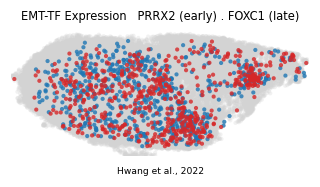

In [5]:
xl = adata.obsm['X_umap']
xlo,xhi=np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi=np.percentile(xl[:,1],[0.3,99.7]); px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g):
    x=adata[:,g].X; return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr={}
for g in [early_tf, late_tf]:
    v=_vec(g); pos=v[v>0]; thr[g]=float(np.quantile(pos,0.75)) if pos.size else 0.0
sel={g:_vec(g)>thr[g] for g in [early_tf,late_tf]}
print('overlay thresholds (upper quartile among expressers):', {g:round(thr[g],3) for g in thr},
      '| cells shown:', {g:int(sel[g].sum()) for g in sel})
order=sorted([early_tf,late_tf], key=lambda g:-int(sel[g].sum())); colors={early_tf:'tab:blue',late_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap=adata[sel[g]].copy(); sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title(f'EMT-TF Expression   {early_tf} (early) . {late_tf} (late)', size=7.5)
ax.text(.5,-.14,'Hwang et al., 2022', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight'); plt.show()
for g in [early_tf,late_tf]:
    m=sel[g]; print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown; mean pt of shown = {tn[m].mean():.2f} (all {tn.mean():.2f})')
print('saved expression.pdf')